### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Final Exam [65 points total]

### Due: Tuesday, 24 November, 2026, 11:59 pm. NO EXTENSIONS, NO SUBMISSION ACCEPTED PAST DUE DATE/TIME.
---

## Problem 1 [30 points total]

One of the most important revelations in modern cosmology was the accelerated expansion of the Universe, interpreted as being caused by a non-zero Cosmological Constant. In this question you will use a simulated sample of Type Ia supernovae to infer the composition of the Universe. 

1. Load in `astr8070_final_cosmodata.npy`, which can be found in the Github repo under `coursework/final/final_data`. The first column is the SN redshift, the second is the distance modulus, and the third is the Gaussian uncertainty on this distance modulus. Make a labeled scatter plot of the data. [2 points]


2. Plot a line on top of this showing the relationship between the distance modulus and the redshift for the current concordance cosmology. You will need to look up the definition of the distance modulus, look up current reasonable cosmological parameters (cite your source), and plot the relationship. *Hint: check astropy.* [3 points]


3. Create a log-likelihood function that reads in the data and accepts values for the Hubble constant, $H_0$, and the fractional energy density in matter, $\Omega_M$. Assume a flat cosmological geometry, such that $\Omega_M + \Omega_\Lambda=1$. Your function should take $H_0$ and $\Omega_M$, and create a model for the distance moduli values at the redshifts of the samples, then compute the log-likelihood for the data. Print out the log-likelihood value at the cosmological parameter values that you used in (2). For maximum points, make sure your log-likelihood function is vectorized over the data samples. [6 points]


4. Perform an MCMC with appropriate diagnostic checks (either manually yourself, or fine if performed by the sampler you employ) over the $\{H_0, \Omega_M\}$ parameter space. Assume priors of $H_0 \in U[50,100]$ km.s$^{-1}$.Mpc$^{-1}$, and $\Omega_M \in U[0,1]$. Make a labeled corner plot showing the $1$D and $2$D marginalized posterior probability distribution of these parameters. State the median value of the $1$D marginal posteriors for each, along with the values enclosing the $68\%$ credible region. [8 points]


5. Draw $100$ random samples from your posterior chain and plot the corresponding band of solutions that are consistent with the data on the distance-modulus--vs--redshift plot along with the original data. [4 points]


6. Now, using an appropriate technique, find the Bayesian log-evidence of your $\{H_0,\Omega_M\}$ model above. Also find the log-evidence of a model with $\Omega_M=1$ such that $H_0$ is the only varied parameter. What is the Bayes factor for the presence of a Cosmological Constant given these data? [7 points] 

In [1]:
#part 1
#imports
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#load data
data = np.load("final_data/astr8070_final_cosmodata.npy")

In [3]:
#assign columns
z = data[:, 0]
mu = data[:, 1]
sigma_mu = data[:, 2]

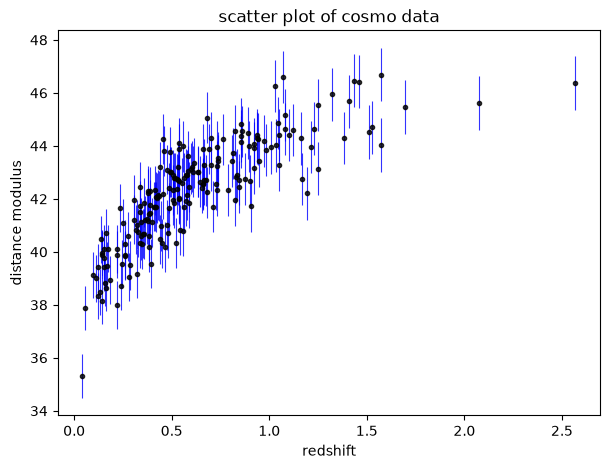

In [4]:
#plot
fig, ax = plt.subplots(figsize=(7, 5))

#error
ax.errorbar(z, mu, yerr=sigma_mu, fmt="o",
            ms=3, color="black", 
            ecolor="blue", elinewidth=0.8, capsize=0, alpha=0.8)

#labels and titles
ax.set_xlabel("redshift")
ax.set_ylabel("distance modulus")
ax.set_title("scatter plot of cosmo data")
plt.show()

In [5]:
#part 2
#import
from astropy.cosmology import FlatLambdaCDM

In [6]:
#cosmological parameters
cosmo = FlatLambdaCDM(H0=67.4, Om0=0.315)

source: "Assuming the base-ΛCDM cosmology, the inferred (model-dependent) late-Universe parameters are: Hubble constant H0 = (67.4 ± 0.5) km s-1 Mpc-1; matter density parameter Ωm = 0.315 ± 0.007..."

Planck Collaboration, Aghanim, N., Akrami, Y., Ashdown, M., Aumont, J., Baccigalupi, C., Ballardini, M., Banday, A. J., Barreiro, R. B., Bartolo, N., et al. 2020, *Astronomy & Astrophysics*, 641, A6. "Planck 2018 results. VI. Cosmological parameters." [doi:10.1051/0004-6361/201833910](https://doi.org/10.1051/0004-6361/201833910), arXiv:[1807.06209](https://arxiv.org/abs/1807.06209)

In [7]:
#grid for redshifts
z_grid = np.linspace(z.min(), z.max(), 500)

In [8]:
#distance modulus from astropy
dist_mod = cosmo.distmod(z_grid).value

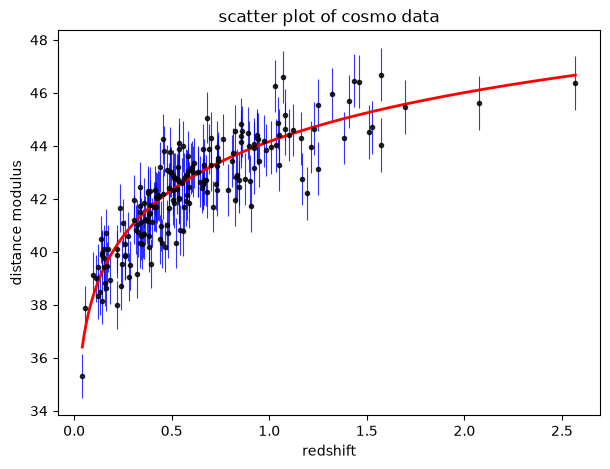

In [9]:
#plot
fig, ax = plt.subplots(figsize=(7, 5))

#error
ax.errorbar(z, mu, yerr=sigma_mu, fmt="o",
            ms=3, color="black", 
            ecolor="blue", elinewidth=0.8, capsize=0, alpha=0.8)

#relationship
ax.plot(z_grid, dist_mod, color="red", lw=2)

#labels and titles
ax.set_xlabel("redshift")
ax.set_ylabel("distance modulus")
ax.set_title("scatter plot of cosmo data")
plt.show()

In [10]:
#part 3
#log-likelihood function
def log_likelihood(H0, Om0, z=z, mu_obs=mu, sigma=sigma_mu):
    cosmo = FlatLambdaCDM(H0=H0, Om0=Om0)
    dist_mod = cosmo.distmod(z).value
    mus = mu_obs - dist_mod
    return -0.5 * np.sum(mus**2 / sigma**2 + np.log(2 * np.pi * sigma**2))

In [11]:
loglikelihood = log_likelihood(67.4, 0.315)
print("log likelihood:", loglikelihood)

log likelihood: -268.1420089351839


In [12]:
#part 4
#imports
import emcee
import corner

In [13]:
#posterior function
def log_posterior(theta):
    H0, Om0 = theta
    #prior bounds given
    if not (50 < H0 < 100 and 0 < Om0 < 1):
        return -np.inf
    return log_likelihood(H0, Om0)

In [14]:
#number of free parameters
ndim = 2
#chosen number of walkers
nwalkers = 16
#chosen numbers of steps
nsteps = 2000

In [15]:
#random number generator
rng = np.random.default_rng(42)

In [16]:
#starting points
start = np.array([67.4, 0.315]) + 1e-3 * rng.standard_normal((nwalkers, ndim))

In [17]:
#set up sampler
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
#run sampler
sampler.run_mcmc(start, nsteps, progress=True)

100%|██████████| 2000/2000 [07:00<00:00,  4.76it/s]


State([[65.71213279  0.55176264]
 [66.16037677  0.56042924]
 [59.57620161  0.87626943]
 [77.44924536  0.13714914]
 [71.35102149  0.26759635]
 [72.07356218  0.20617373]
 [69.79384192  0.50447434]
 [73.88044266  0.17651337]
 [70.92452707  0.23555713]
 [73.25552158  0.2763486 ]
 [67.8100448   0.70229684]
 [75.14918137  0.27454336]
 [78.35177265  0.12822652]
 [65.80809764  0.53143514]
 [72.86616395  0.28508515]
 [75.0132926   0.24486917]], log_prob=[-267.32861938 -267.34346306 -269.41814578 -266.62869186 -266.44838968
 -266.93613083 -267.84571559 -266.67310204 -267.03595493 -266.29396064
 -270.27158307 -266.87105879 -266.76933234 -267.26947129 -266.28712451
 -266.45734312], blobs=None, random_state=('MT19937', array([3038072261, 3057263982,  758766244,  731555548, 3550311348,
       3190471818, 2099774469,  311206870,  949612435, 1500261465,
       3887198575,   26606960, 2265159662, 2440763144,   55116731,
       3179756351, 2359628263, 3832071350, 3194511694, 2165599014,
       309238220

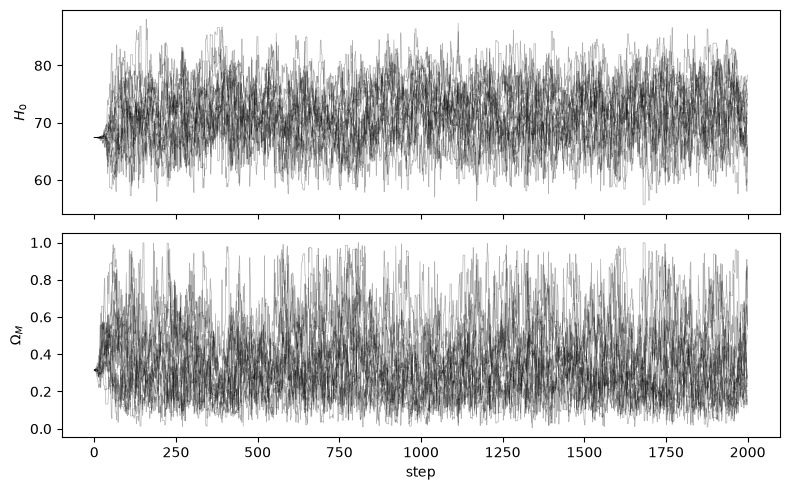

In [18]:
#trace plots
labels = ["$H_0$", r"$\Omega_M$"]

fig, axes = plt.subplots(ndim, 1, figsize=(8, 5), sharex=True)

#get chain
chain = sampler.get_chain()     

#loop over parameters
for i in range(ndim):
    axes[i].plot(chain[:, :, i], "k", alpha=0.3, lw=0.5)
    axes[i].set_ylabel(labels[i])
axes[-1].set_xlabel("step")
fig.tight_layout()

In [19]:
#check for correct behavior
#integrated autocorrelation time
tau = sampler.get_autocorr_time()
print("tau =", tau)
print("nsteps / tau =", nsteps / tau)   
print("mean acceptance fraction =", np.mean(sampler.acceptance_fraction))

tau = [39.92880159 34.85422721]
nsteps / tau = [50.0891567  57.38184892]
mean acceptance fraction = 0.7087187500000001


In [20]:
#burn in
burn = 125

#thinning
thin = max(1, int(np.max(tau) / 2))
samples1 = sampler.get_chain(discard=burn, thin=thin, flat=True)

medians: [71.56430836  0.31163002]
+ errors: [4.83811619 0.20931386]
- errors: [5.05497991 0.1450474 ]


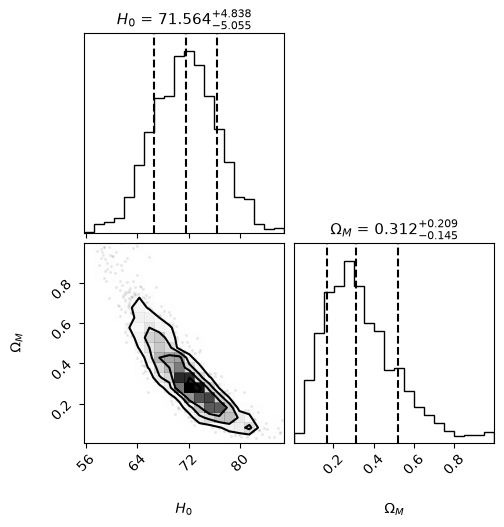

In [21]:
#corner plot
fig = corner.corner(samples1, labels=labels, quantiles=[0.16, 0.5, 0.84],
                    show_titles=True, title_fmt=".3f", title_kwargs={"fontsize": 11})

#get percentile values
lo, med, hi = np.percentile(samples1, [16, 50, 84], axis=0)
print("medians:", med)
print("+ errors:", hi - med)
print("- errors:", med - lo)

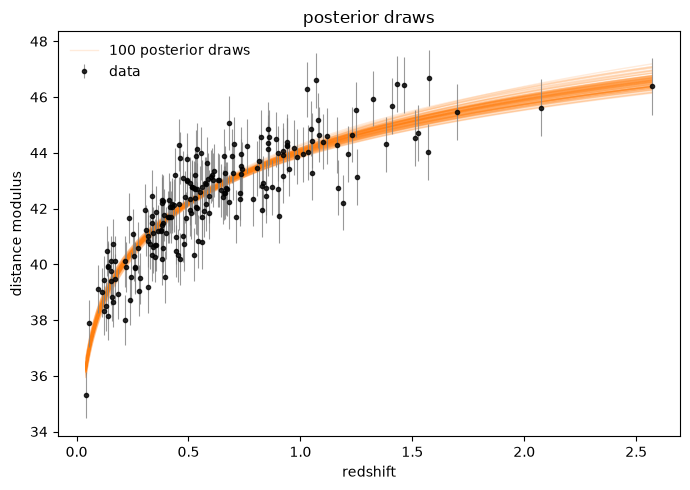

In [22]:
#part 5
#plot
fig, ax = plt.subplots(figsize=(7, 5))
#errors
ax.errorbar(z, mu, yerr=sigma_mu, fmt="o", ms=3, color="black", ecolor="gray",
            elinewidth=0.8, alpha=0.8, zorder=2, label="data")
ax.set_xlabel("redshift")
ax.set_ylabel("distance modulus")
ax.set_title("posterior draws")

#100 random samples
idx = rng.choice(len(samples1), size=100, replace=False)

for k, i in enumerate(idx):
    H0_i, Om_i = samples1[i]
    #cosmology, calculate distance modulus
    mu_i = FlatLambdaCDM(H0=H0_i, Om0=Om_i).distmod(z_grid).value
    #plot
    ax.plot(z_grid, mu_i, color="C1", alpha=0.15, lw=1, zorder=1,
            label="100 posterior draws" if k == 0 else None)

ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [23]:
#part 6
#imports
import dynesty
from scipy.special import logsumexp

In [24]:
#prior transform function
def prior_transform(u):
    return np.array([50 + 50 * u[0], u[1]])

#set up log likelihood for dynesty
def lnL(theta):
    return log_likelihood(*theta)

In [25]:
#set up sampler
ns = dynesty.NestedSampler(lnL, prior_transform, ndim=2, nlive=500)
#run sampler
ns.run_nested()
#get results
res = ns.results

#get lnZ and its error for free omega
lnZ1, lnZ1_err = res.logz[-1], res.logzerr[-1]
print(f"ln Z (LCDM) = {lnZ1:.2f} +/- {lnZ1_err:.2f}")

100%|█████████▉| 1973/1974 [03:58<00:00,  8.27it/s, +500 | bound: 1 | nc: 1 | ncall: 18641 | eff(%): 13.632 | loglstar: -266.228 | logz: -269.342 +/-  0.066 | dlogz:  0.001 >  0.509]

ln Z (LCDM) = -269.34 +/- 0.13


In [26]:
#omega = 1
#H0 grid
H0_grid = np.linspace(50, 100, 501)
#evaluate log likelihood at each H0 grid value
lnL_grid = np.array([log_likelihood(h, 1.0) for h in H0_grid])

#grid spacing
dH = H0_grid[1] - H0_grid[0]
#weights
w = np.full(len(H0_grid), dH); w[[0, -1]] *= 0.5

#get lnZ
lnZ2 = logsumexp(lnL_grid, b=w) - np.log(50)
print(f"ln Z (omega = 1) = {lnZ2:.2f}")

ln Z (omega = 1) = -272.17


In [27]:
#calculate Bayes factor
lnB = lnZ1 - lnZ2
print(f"ln B = {lnB:.2f},  B = {np.exp(lnB):.3g}")

ln B = 2.83,  B = 17


In [28]:
print("Bayes factor:", f"B = {np.exp(lnB):.3g}")
print("data favors model with free omega")

Bayes factor: B = 17
data favors model with free omega


## Problem 2 [35 points total]

There are several empirical scaling relationships between the masses of black holes in galaxy centers and the properties of their hosts. In this problem you will use real data from the "MASSIVE" Galaxy Survey. This data updates that used in [McConnell & Ma (2013)](https://ui.adsabs.harvard.edu/abs/2013ApJ...764..184M/abstract), which presented a systematic investigation of scaling relations with different catalog subsets.

1. Download this dataset: http://blackhole.berkeley.edu/wp-content/uploads/2016/09/current_ascii.txt. Skip the appropriate header rows and read this into a `pandas` dataframe. Use the meta-data in the header rows to create appropriate column names for your dataframe. Make sure that your data file is properly formatted with tab-spaced columns so that it is readable without errors. [3 points]


2. Create a data matrix out of the base-10 log values of: the galaxy distance, the velocity dispersion $\sigma$, and the black hole mass. Create a target vector that has $1$ for early-type galaxies (morphology has `E` or `S0` in the value) and $0$ for late-type galaxies. Print out the number of early-type and late-type galaxies that are in your target vector, as well as the total number of galaxies. [3 points]


3. Perform a 50-50 train-test split on the data matrix and target vector, using `random_state=0` for reproducibility. Train the following classifiers, overplotting ROC curves for all:
    - Gaussian Naive Bayes
    - LDA
    - QDA
    - $K$-nearest neighbors (with $K=10$)
    - Gaussian mixture model (with $2$ components)
    - Decision Tree (with `entropy` criterion, and tree depth $=2$)
 [5 points]
    

4. What minimum tree depth do you need to achieve essentially perfect classification accuracy with the Decision Tree? Confirm this by making a two-panel figure with scatter plots of the log10-distance and log10-sigma from the test data, color-coded by the test label (left panel) and predicted label (right panel).  [3 points]


5. The following regression tasks should all produce best-fit regression coefficients and a plot. State how many galaxies are being fit in each scenario.
    - Use the $68\%$ low and high black-hole mass values to deduce the uncertainty on each $(M_\mathrm{BH}/M_\odot)$. Convert this into an uncertainty on $\log_{10}(M_\mathrm{BH}/M_\odot)$. Ignoring the uncertainties on $\sigma$, perform linear regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$$
and state the best-fit regression coefficients $\{\alpha,\beta\}$. Plot the best-fit line on a scatter plot with the data. 
    - Repeat the previous bullet to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(L_V \,/\, 10^{11}L_\odot)$$ for the sub-sample of galaxies with $V$-band luminosity data (ignoring the $L_V$ uncertainties).
    - Repeat to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(M_\mathrm{bulge} \,/\, 10^{11}M_\odot)$$ for the sub-sample of galaxies with bulge mass measurements (ignoring the $M_\mathrm{bulge}$ uncertainties).
 [7 points]
 
 
6. Perform polynomial regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \sum_{p=1}^{N_p}\beta_p[\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})]^p.$$
For $N_p$ in the range $0$ to $5$, fit the polynomial relationship, print the regression coefficients, and compute the BIC value. Make a labeled plot of the BIC versus the polynomial degree. Is a quadratic or higher polynomial relationship between $\log_{10}(M_\mathrm{BH}/M_\odot)$ and $\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$ favored? [5 points]


7. Perform linear regression ($N_p=1$) on the dataset on sub-samples of early-type and late-type galaxies. Print the best-fit regression coefficients from each of these sub-sets. Make a scatter plot that includes the original data color coded by early/late type, the fit to all of the data, and the fits from the early/late-type sub-samples. The plot should have appropriate labels and a legend. [4 points]

In [29]:
#part 1
#import
import pandas as pd

In [30]:
#filename
fname = "current_ascii.txt"

In [31]:
#column names taken from current_ascii file
names = [
    "galaxy", "distance_Mpc",
    "MBH", "MBH_lo", "MBH_hi",            
    "method",
    "sigma", "sigma_lo", "sigma_hi",      
    "logLV", "logLV_err",                 
    "logL36", "logL36_err",               
    "Mbulge",                             
    "r_infl_arcsec",
    "morphology", "profile",
    "Reff_V_arcsec", "Reff_i_arcsec", "Reff_36_arcsec",
]

In [32]:
#read in data
with open(fname, "r", errors="replace") as f:
    lines = f.readlines()

#data starts at first lines with tabs, skipping over headers
first = next(i for i, l in enumerate(lines) if "\t" in l)
print("header rows skipped:", first)

#fix formatting problems
rows = []
for l in lines[first:]:
    #skip blank lines
    if not l.strip():
        continue
    #removes trailing tabs
    l = l.rstrip("\t\n") 
    #builds lines with proper tabs
    if len(l.split("\t")) != len(names):  
        parts = l.split()
        assert len(parts) == len(names), (len(parts), l)
        l = "\t".join(parts)
    #adds corrected line to list
    rows.append(l)

#save clean copy with fixed rows
with open("current_clean.txt", "w") as f:
    f.write("\n".join(rows) + "\n")

#load the clean file into pandas
df = pd.read_csv("current_clean.txt", sep="\t", header=None,
                 names=names, keep_default_na=False)

#check data
print(df.shape)       
print(df.dtypes)
df.head()

header rows skipped: 25
(78, 20)
galaxy                str
distance_Mpc      float64
MBH               float64
MBH_lo            float64
MBH_hi            float64
method                str
sigma             float64
sigma_lo          float64
sigma_hi          float64
logLV             float64
logLV_err         float64
logL36            float64
logL36_err        float64
Mbulge            float64
r_infl_arcsec     float64
morphology            str
profile               str
Reff_V_arcsec     float64
Reff_i_arcsec     float64
Reff_36_arcsec    float64
dtype: object


,galaxy,distance_Mpc,MBH,MBH_lo,MBH_hi,method,sigma,sigma_lo,sigma_hi,logLV,logLV_err,logL36,logL36_err,Mbulge,r_infl_arcsec,morphology,profile,Reff_V_arcsec,Reff_i_arcsec,Reff_36_arcsec
0,MW,0.008,4.100000e+06,3.500000e+06,4.700000e+06,star,103.0,83.0,123.0,0.00,0.00,0.00,0.00,0.000000e+00,43.00,S,N/A,0.0,0.00,0.00
1,A1836,157.500,3.900000e+09,3.300000e+09,4.300000e+09,gas,288.0,274.0,302.0,11.26,0.06,0.00,0.00,0.000000e+00,0.27,E,C,0.0,17.61,0.00
2,A3565,54.400,1.400000e+09,1.200000e+09,1.700000e+09,gas,322.0,306.0,338.0,11.24,0.06,0.00,0.00,0.000000e+00,0.22,E,C,0.0,0.00,0.00
3,Circ,4.000,1.700000e+06,1.400000e+06,2.100000e+06,maser,158.0,140.0,176.0,0.00,0.00,10.31,0.02,0.000000e+00,0.02,S,N/A,0.0,0.00,10.83
4,IC1459,30.900,2.700000e+09,2.300000e+09,3.000000e+09,star,315.0,299.0,331.0,10.96,0.06,11.82,0.12,3.070000e+11,0.81,E,C,29.8,0.00,61.10


In [33]:
#part 2
#create data matrix as a numpy array
X = np.log10(df[["distance_Mpc", "sigma", "MBH"]].to_numpy())

#target vector as a numpy array
y = df["morphology"].str.contains("E|S0").astype(int).to_numpy()

print("data matrix shape:", X.shape)
print("early-type (1):", (y == 1).sum())
print("late-type (0): ", (y == 0).sum())
print("total galaxies:", len(y))

data matrix shape: (78, 3)
early-type (1): 59
late-type (0):  19
total galaxies: 78


In [34]:
#part 3
#imports 
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_curve, auc

In [35]:
#train-test split on the data matrix (X) and target vector (y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

In [36]:
#set up the classifiers listed
#GMM handled separately in plotting cell
classifiers = {
    "Gaussian NB": GaussianNB(),
    "LDA": LDA(),
    "QDA": QDA(),
    "KNN (K=10)": KNeighborsClassifier(n_neighbors=10),
    "Decision tree (depth 2)": DecisionTreeClassifier(criterion="entropy", max_depth=2),
}

C:\Users\sydne\New folder\envs\astr5300\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sydne\New folder\envs\astr5300\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


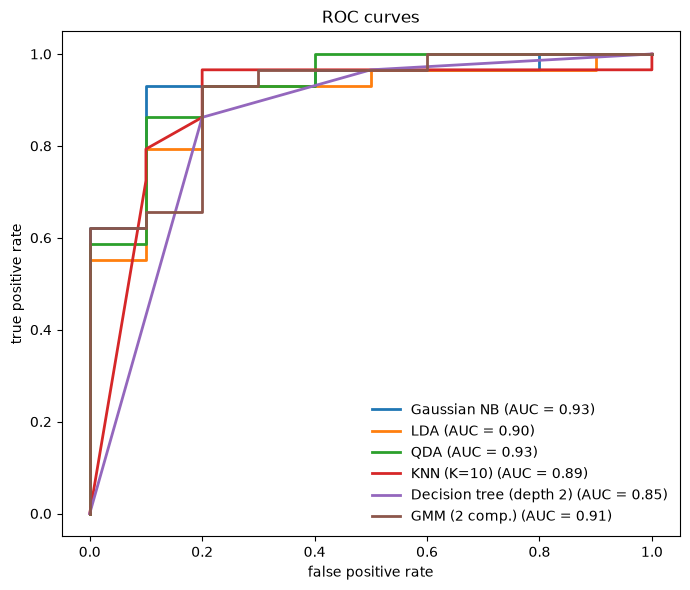

In [37]:
#plot
fig, ax = plt.subplots(figsize=(7, 6))

#loop over supervised classifiers
for name, clf in classifiers.items():
    #train each classifier
    clf.fit(X_train, y_train)
    #get predicted probability of each class
    p = clf.predict_proba(X_test)[:, 1]      
    #compare probabilties with true test labels and get false/true positive rates
    fpr, tpr, _ = roc_curve(y_test, p)
    #plot roc curve and get area under curve
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")

#gaussian mixture model
g0 = GaussianMixture(n_components=2, random_state=0).fit(X_train[y_train == 0])
g1 = GaussianMixture(n_components=2, random_state=0).fit(X_train[y_train == 1])
#log-likelihood ratio, early-type vs late-type
score = g1.score_samples(X_test) - g0.score_samples(X_test)
#false and true positive rates
fpr, tpr, _ = roc_curve(y_test, score)
#plot roc curve and get area under curve
ax.plot(fpr, tpr, lw=2, label=f"GMM (2 comp.) (AUC = {auc(fpr, tpr):.2f})")

#additional plot parameters
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC curves")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

In [38]:
#part 4
#import
from sklearn.metrics import accuracy_score

In [39]:
#depths to test
depths = range(1, 11)
#loop over depths to determine best
for d in depths:
    #build decision tree
    tree = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0).fit(X_train, y_train)
    #training accuracy on training and test galaxies
    tr = accuracy_score(y_train, tree.predict(X_train))
    te = accuracy_score(y_test, tree.predict(X_test))
    print(f"depth {d:2d}: train acc = {tr:.3f}, test acc = {te:.3f}, leaves = {tree.get_n_leaves()}")

depth  1: train acc = 0.846, test acc = 0.846, leaves = 2
depth  2: train acc = 0.872, test acc = 0.846, leaves = 3
depth  3: train acc = 0.949, test acc = 0.846, leaves = 4
depth  4: train acc = 0.974, test acc = 0.846, leaves = 5
depth  5: train acc = 1.000, test acc = 0.872, leaves = 6
depth  6: train acc = 1.000, test acc = 0.872, leaves = 6
depth  7: train acc = 1.000, test acc = 0.872, leaves = 6
depth  8: train acc = 1.000, test acc = 0.872, leaves = 6
depth  9: train acc = 1.000, test acc = 0.872, leaves = 6
depth 10: train acc = 1.000, test acc = 0.872, leaves = 6


In [40]:
#best depth is 5 because:
#it reaches training accuracy of 1
#test accuracy stops growing
#number of leaves stops growing
best_depth = 5

In [41]:
#build decision tree using best depth
tree = DecisionTreeClassifier(criterion="entropy", max_depth=best_depth, random_state=0).fit(X_train, y_train)
#predict labels for each galaxy
y_pred = tree.predict(X_test)
print("best depth:", best_depth)
print("test accuracy:", accuracy_score(y_test, y_pred))

best depth: 5
test accuracy: 0.8717948717948718


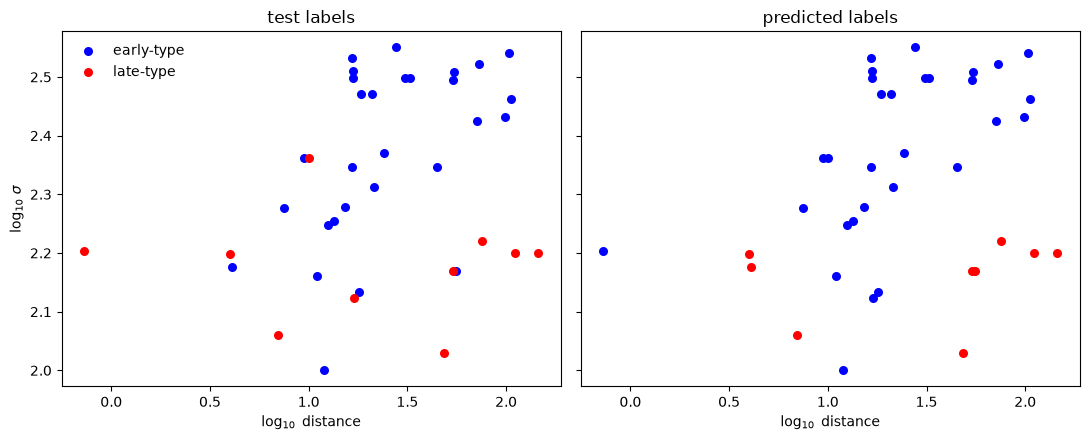

In [42]:
#plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

#loop over true labels and predicted labels
for ax, lab, title in zip(axes, [y_test, y_pred],
                          #titles for two plots
                          ["test labels", "predicted labels"]):
    #pick out galaxies labeled early-type
    ax.scatter(X_test[lab == 1, 0], X_test[lab == 1, 1], c="blue", s=30, label="early-type")
    ax.scatter(X_test[lab == 0, 0], X_test[lab == 0, 1], c="red", s=30, label="late-type")
    ax.set_xlabel(r"$\log_{10}$ distance")
    ax.set_title(title)

#other plot parameters
axes[0].set_ylabel(r"$\log_{10}\,\sigma$")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

In [43]:
#part 5
#import
from scipy.optimize import curve_fit

In [44]:
#get uncertainties on masses
#get base 10 log on black hole masses
logM = np.log10(df["MBH"])
#error bars from log of the 68% bounds 
err_lo = logM - np.log10(df["MBH_lo"])
err_hi = np.log10(df["MBH_hi"]) - logM

#uncertainty on M_BH, from the 68% low and high values
sigma_M = 0.5 * (df["MBH_hi"] - df["MBH_lo"])
#convert to an uncertainty on log10(M_BH)
df["logM"] = logM
df["logM_err"] = sigma_M / (df["MBH"] * np.log(10))      

In [45]:
#function to fit and plot different relations with linear regression
def fit_and_plot(x, y, yerr, xlabel, title, asym=None, name=None):
    #model is a straight line with intercept a and slope b
    line = lambda x, a, b: a + b * x
    #get best fit and covariance
    popt, pcov = curve_fit(line, x, y, sigma=yerr, absolute_sigma=True)
    #1 sigma uncertainties of alpha and beta
    perr = np.sqrt(np.diag(pcov))
    #chi squared
    chi2 = np.sum(((y - line(x, *popt)) / yerr) ** 2)
    #print values
    print(f"{name or title}: number of galaxies = {len(x)}")
    print(f"  alpha = {popt[0]:.3f} +/- {perr[0]:.3f}")
    print(f"  beta  = {popt[1]:.3f} +/- {perr[1]:.3f}")
    print(f"  chi2/dof = {chi2 / (len(x) - 2):.2f}")

    #plot
    fig, ax = plt.subplots(figsize=(6.5, 5))
    #error bars
    ax.errorbar(x, y, yerr=asym if asym is not None else yerr, fmt="o", ms=4,
                color="k", ecolor="gray", elinewidth=0.8, label=f"number of galaxies = {len(x)}")
    xg = np.linspace(x.min(), x.max(), 100)
    #plot best-fit line
    ax.plot(xg, line(xg, *popt), "r-", lw=2,
            label=rf"$\alpha$ = {popt[0]:.2f}, $\beta$ = {popt[1]:.2f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()
    return popt, perr

sigma: number of galaxies = 78
  alpha = 8.010 +/- 0.003
  beta  = 2.090 +/- 0.015
  chi2/dof = 831.15


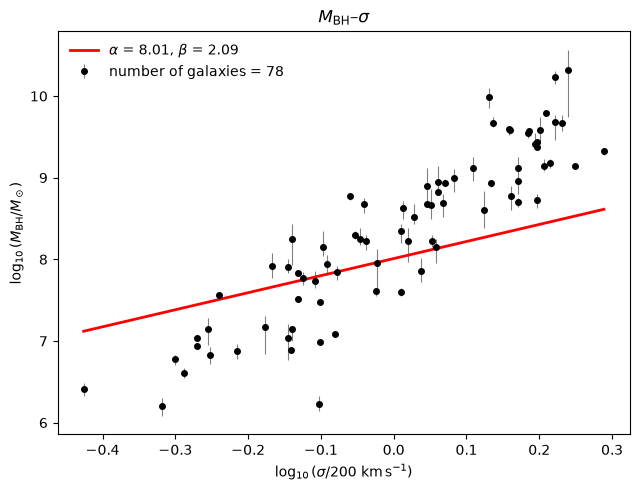

L_V: number of galaxies = 48
  alpha = 9.440 +/- 0.009
  beta  = 1.025 +/- 0.017
  chi2/dof = 63.37


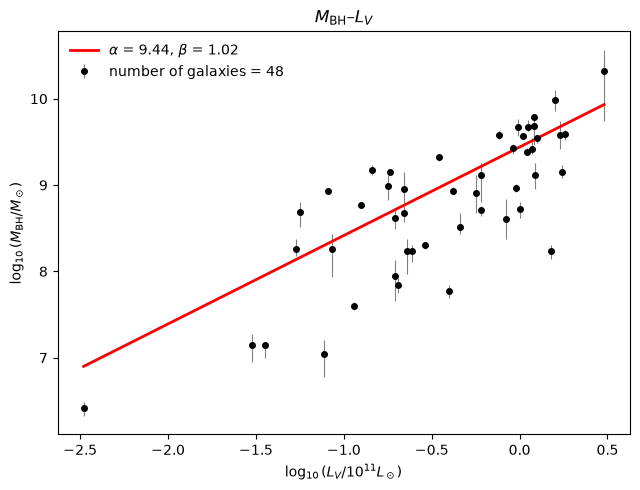

M_bulge: number of galaxies = 38
  alpha = 8.572 +/- 0.013
  beta  = 0.957 +/- 0.017
  chi2/dof = 51.74


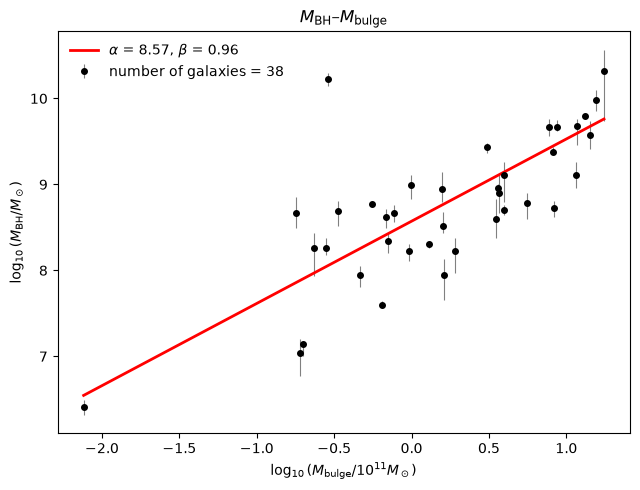

In [46]:
#first relation
m = df["sigma"] > 0
d = df[m]
fit_sigma = fit_and_plot(np.log10(d["sigma"] / 200).to_numpy(), d["logM"].to_numpy(),
                         d["logM_err"].to_numpy(),
                         r"$\log_{10}(\sigma / 200\ {\rm km\,s^{-1}})$", title=r"$M_{\rm BH}$–$\sigma$",
                         name = "sigma",
                         asym=[err_lo[m].to_numpy(), err_hi[m].to_numpy()])

#second relation
m = df["logLV"] > 0
d = df[m]
fit_L = fit_and_plot((d["logLV"] - 11).to_numpy(), d["logM"].to_numpy(),
                     d["logM_err"].to_numpy(),
                     r"$\log_{10}(L_V / 10^{11} L_\odot)$", title=r"$M_{\rm BH}$–$L_V$",
                     name = "L_V",
                     asym=[err_lo[m].to_numpy(), err_hi[m].to_numpy()])

#third relation
m = df["Mbulge"] > 0
d = df[m]
fit_Mb = fit_and_plot((np.log10(d["Mbulge"]) - 11).to_numpy(), d["logM"].to_numpy(),
                      d["logM_err"].to_numpy(),
                      r"$\log_{10}(M_{\rm bulge} / 10^{11} M_\odot)$", title=r"$M_{\rm BH}$–$M_{\rm bulge}$",
                      name = "M_bulge",
                      asym=[err_lo[m].to_numpy(), err_hi[m].to_numpy()])

In [47]:
#part 6
#assign data
d = df[df["sigma"] > 0]
x = np.log10(d["sigma"].to_numpy() / 200)
y = d["logM"].to_numpy()
s = d["logM_err"].to_numpy()
N = len(x)
print("number of galaxies:", N)

number of galaxies: 78


In [48]:
#values of N_p to try
degrees = np.arange(0, 6)

#get one bic per degree
bics = []
print("highest power first, alpha last")
for Np in degrees:
    #fit polynomial and get coefficients
    coef = np.polyfit(x, y, Np, w=1 / s)  
    #get residuals
    resid = y - np.polyval(coef, x)
    #get chi squared
    chi2 = np.sum((resid / s) ** 2)
    #get log likelihood
    lnL = -0.5 * (chi2 + np.sum(np.log(2 * np.pi * s**2)))
    #number of free parameters
    k = Np + 1                    
    #get bic
    bic = k * np.log(N) - 2 * lnL
    bics.append(bic)
    print(f"Np = {Np}: coefficients = {np.round(coef, 3)}, BIC = {bic:.1f}")

highest power first, alpha last
Np = 0: coefficients = [7.557], BIC = 82216.6
Np = 1: coefficients = [2.09 8.01], BIC = 62899.7
Np = 2: coefficients = [19.379  5.284  7.69 ], BIC = 27907.3
Np = 3: coefficients = [-35.138  14.778   6.799   7.831], BIC = 26604.8
Np = 4: coefficients = [-385.191  -94.605   34.578    9.45     7.795], BIC = 17568.1
Np = 5: coefficients = [ 313.719 -285.938 -120.946   27.441    9.909    7.872], BIC = 17352.9


In [49]:
#create numpy array of calculated bic values
bics = np.array(bics)

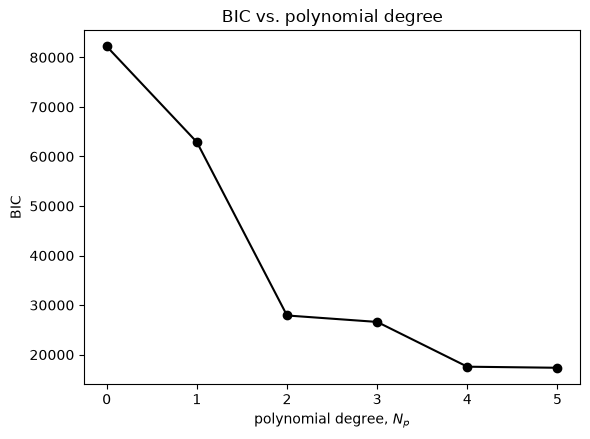

In [50]:
#plot of bic vs polynomial degree
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(degrees, bics, "ko-")
ax.set_xlabel(r"polynomial degree, $N_p$")
ax.set_ylabel("BIC")
ax.set_title(r"BIC vs. polynomial degree")
fig.tight_layout()
plt.show()

In [51]:
#higher polynomial relationship is favored because bic decreases
#N_p = 5 is most favored

In [52]:
#part 7
#assign data
d = df[df["sigma"] > 0].copy()
d["x"] = np.log10(d["sigma"] / 200)
d["early"] = d["morphology"].str.contains("E|S0")    

In [53]:
#function to fit line to groups
def wfit(sub):
    #get coefficients and covariances
    coef, cov = np.polyfit(sub["x"], sub["logM"], 1, w=1 / sub["logM_err"], cov="unscaled")
    #return best fit and errors
    return coef[::-1], np.sqrt(np.diag(cov))[::-1]     

In [54]:
#split data into sub-samples of all galaxies, early, and late type
samples = {"all": d, "early-type": d[d["early"]], "late-type": d[~d["early"]]}

#dictionary to hold best fit
fits = {}

#get best fit and errors for each sub-sample
for name, sub in samples.items():
    (a, b), (ea, eb) = wfit(sub)
    #save to dictionary
    fits[name] = (a, b)
    #print best fit regression coefficients
    print(f"{name:11s}: number of galaxies = {len(sub):2d}, alpha = {a:.3f} +/- {ea:.3f}, beta = {b:.3f} +/- {eb:.3f}")

all        : number of galaxies = 78, alpha = 8.010 +/- 0.003, beta = 2.090 +/- 0.015
early-type : number of galaxies = 59, alpha = 8.449 +/- 0.007, beta = 4.891 +/- 0.047
late-type  : number of galaxies = 19, alpha = 7.004 +/- 0.006, beta = -2.256 +/- 0.025


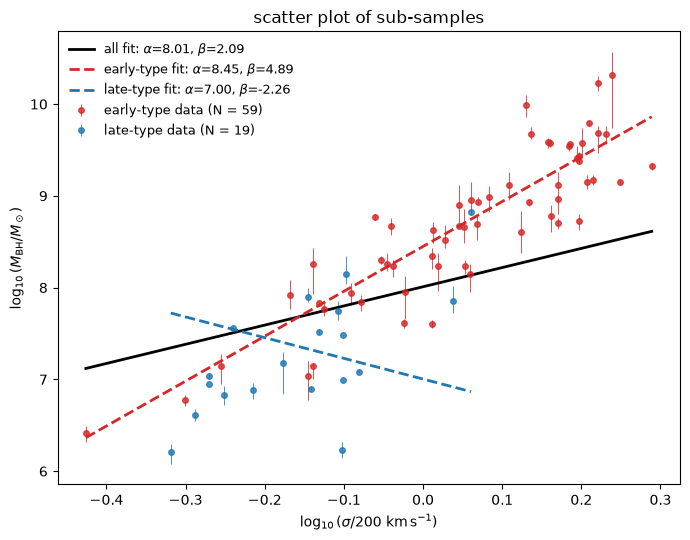

In [55]:
#make scatter plot
fig, ax = plt.subplots(figsize=(7, 5.5))

#loop twice over early and late
for name, color in [("early-type", "C3"), ("late-type", "C0")]:
    #galaxies for each type
    sub = samples[name]
    #plot errorbars
    ax.errorbar(sub["x"], sub["logM"], yerr=[err_lo[sub.index], err_hi[sub.index]],
                fmt="o", ms=4, color=color, ecolor=color, elinewidth=0.7, alpha=0.8,
                label=f"{name} data (N = {len(sub)})")

#x values
xg = np.linspace(d["x"].min(), d["x"].max(), 100)

#line style and color for each type
styles = {"all": ("k", "-"), "early-type": ("C3", "--"), "late-type": ("C0", "--")}

#loop over fits
for name, (a, b) in fits.items():
    #get styles
    c, ls = styles[name]
    #get x range
    xs = xg if name == "all" else np.linspace(samples[name]["x"].min(), samples[name]["x"].max(), 50)
    #plot lines
    ax.plot(xs, a + b * xs, color=c, ls=ls, lw=2,
            label=rf"{name} fit: $\alpha$={a:.2f}, $\beta$={b:.2f}")

#other plot parameters
ax.set_xlabel(r"$\log_{10}(\sigma / 200\ {\rm km\,s^{-1}})$")
ax.set_ylabel(r"$\log_{10}(M_{\rm BH}/M_\odot)$")
ax.set_title("scatter plot of sub-samples")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()